# Notebook 4 — Branqueamento, filtragem e transformada Q
## GW150914 | LIGO Hanford (H1) | Campanha O1

**Objetivo:**

Aplicar técnicas de processamento aos dados reais do GW150914, estudando:
- branqueamento (*whitening*) da série temporal;
- filtragem passa-faixa (*bandpass filtering*);
- transformada Q para visualizar a evolução do sinal no plano tempo-frequência.

> **Como trabalhar:** Execute as células na ordem. Nas pausas **Observe**, interprete os resultados e compare sua saída com a projetada em sala.

**Origem:** Material adaptado de [Introduction to GWOSC Data](https://github.com/gwosc-tutorial/introduction_gwosc_data), sob licença GPL-3.0 ou posterior.

**Adaptação didática:** Ronai Lisbôa — UFRN.

#1. Preparação mínima — dados do Notebook 4

Vamos continuar a análise do GW150914 utilizando o mesmo arquivo HDF5 e os mesmos intervalos de tempo do Notebook 4.

Primeiramente, importamos as bibliotecas e acessamos o arquivo armazenado no Google Drive. Em seguida, definimos duas janelas de observação:
- 16 segundos ao redor do evento, de −8 s a +8 s, para analisar o sinal;
- 128 segundos anteriores ao evento, de −200 s a −72 s, para caracterizar o ruído instrumental.
Esses intervalos serão utilizados nas próximas etapas de processamento.

In [2]:
# Instalar o GWpy somente se necessário
try:
    from gwpy.timeseries import TimeSeries
except ImportError:
    %pip install -q gwpy
    from gwpy.timeseries import TimeSeries

from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "font.size": 14})

# Evento GW150914
GPS_EVENTO = 1126259462.4

# Intervalos de análise
DURACAO_EVENTO = 16
DURACAO_RUIDO = 128

INICIO_EVENTO = GPS_EVENTO - 8
INICIO_RUIDO = GPS_EVENTO - 200

# Acessar o arquivo no Google Drive
from google.colab import drive
drive.mount("/content/drive")

pasta_dados = Path(
    "/content/drive/MyDrive/Colab Notebooks/GWPY-Curso/dados"
)

filename = pasta_dados / "H-H1_LOSC_4_V1-1126256640-4096.hdf5"

if not filename.is_file():
    raise FileNotFoundError(f"Arquivo não encontrado: {filename}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#2. Leitura do HDF5 e ASD de referência

Agora vamos ler apenas as amostras correspondentes aos dois intervalos selecionados, evitando carregar toda a série temporal na memória.

A frequência de amostragem é obtida a partir do atributo Xspacing do arquivo HDF5. Os dados são então armazenados em objetos TimeSeries do GWpy, que associam os valores de strain aos respectivos tempos de observação.

Utilizando os 128 segundos anteriores ao evento, calculamos uma ASD de referência pelo método de Welch, com segmentos de 4 segundos e sobreposição de 2 segundos.

Como a ASD já foi estudada no Notebook 4, não repetiremos seu gráfico. Ela será utilizada nas etapas seguintes de branqueamento e transformada Q.

In [3]:
# Ler apenas os intervalos necessários
with h5py.File(filename, "r") as arquivo:

    dataset = arquivo["strain"]["Strain"]
    gps_start = int(arquivo["meta"]["GPSstart"][()])
    dt = float(dataset.attrs["Xspacing"])
    fs = 1 / dt

    def ler_trecho(inicio, duracao):
        i0 = int(round((inicio - gps_start) / dt))
        n_amostras = int(round(duracao * fs))

        if not (0 <= i0 and i0 + n_amostras <= len(dataset)):
            raise ValueError("Janela fora do intervalo do arquivo")

        return dataset[i0:i0+n_amostras]

    amostras_evento = ler_trecho(INICIO_EVENTO, DURACAO_EVENTO)
    amostras_ruido = ler_trecho(INICIO_RUIDO, DURACAO_RUIDO)

# Criar as séries temporais com GWpy
serie_evento = TimeSeries(
    amostras_evento, sample_rate=fs,
    t0=INICIO_EVENTO, name="H1 — GW150914"
)

serie_ruido = TimeSeries(
    amostras_ruido, sample_rate=fs,
    t0=INICIO_RUIDO, name="H1 — ruído de referência"
)

# Calcular a ASD do ruído de referência
asd_referencia = serie_ruido.asd(
    fftlength=4, overlap=2,
    window="hann", method="welch"
)

print(f"Detector: H1 | GPS do evento: {GPS_EVENTO}")
print(f"Amostragem: {fs:.0f} Hz")
print(f"Evento: {serie_evento.duration.value:.0f} s")
print(f"Referência: {serie_ruido.duration.value:.0f} s")
print("ASD de referência calculada.")

Detector: H1 | GPS do evento: 1126259462.4
Amostragem: 4096 Hz
Evento: 16 s
Referência: 128 s
ASD de referência calculada.


#3. Branqueamento (*whitening*)

No Notebook 4, observamos que o ruído instrumental não tem a mesma intensidade em todas as frequências. O **branqueamento** repondera as componentes espectrais de acordo com a ASD estimada a partir de um trecho sem o evento, tornando o espectro de ruído aproximadamente uniforme.

De modo esquemático, $\widetilde{s}_{\mathrm{white}}(f)\propto \widetilde{s}(f)/\mathrm{ASD}(f)$. O resultado facilita a identificação do sinal, mas **não elimina o ruído** e **não equivale a subtrair** o trecho anterior do evento.

A função `whiten()` do GWpy faz esse processamento no domínio da frequência e devolve uma série temporal.

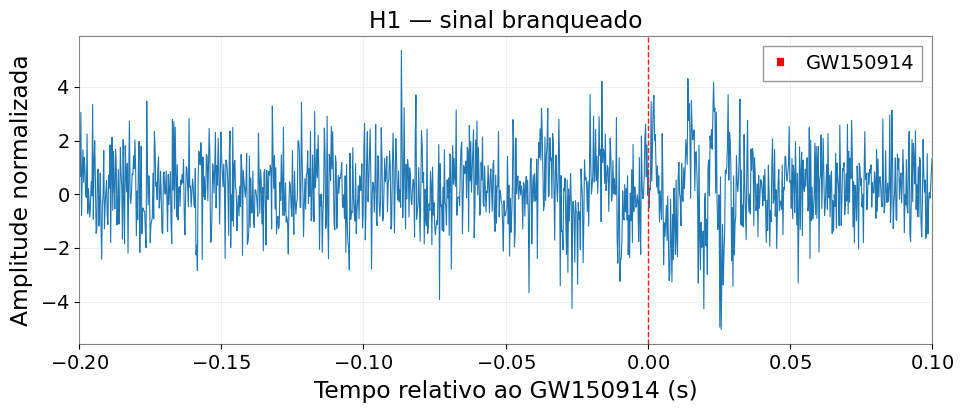

In [7]:
# Branqueamento dos 16 s usando o ruído de referência do Notebook 4.
branqueado = serie_evento.whiten(asd=asd_referencia, fduration=2)

fig, ax = plt.subplots()
ax.plot(branqueado.times.value - GPS_EVENTO, branqueado.value, lw=0.8)
ax.axvline(0, color="red", ls="--", lw=1, label="GW150914")
ax.set(xlim=(-0.2, 0.1), xlabel="Tempo relativo ao GW150914 (s)",
       ylabel="Amplitude normalizada", title="H1 — sinal branqueado")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

#4. Filtragem passa-faixa

Mesmo após o branqueamento, ainda há flutuações em diferentes faixas espectrais. O **filtro passa-faixa** atenua componentes abaixo de **30 Hz** e acima de **400 Hz**, preservando principalmente as componentes dentro desse intervalo.

Aplicaremos o filtro ao **sinal já branqueado**, como no Notebook 6. Compare os dois gráficos com a mesma janela de tempo.

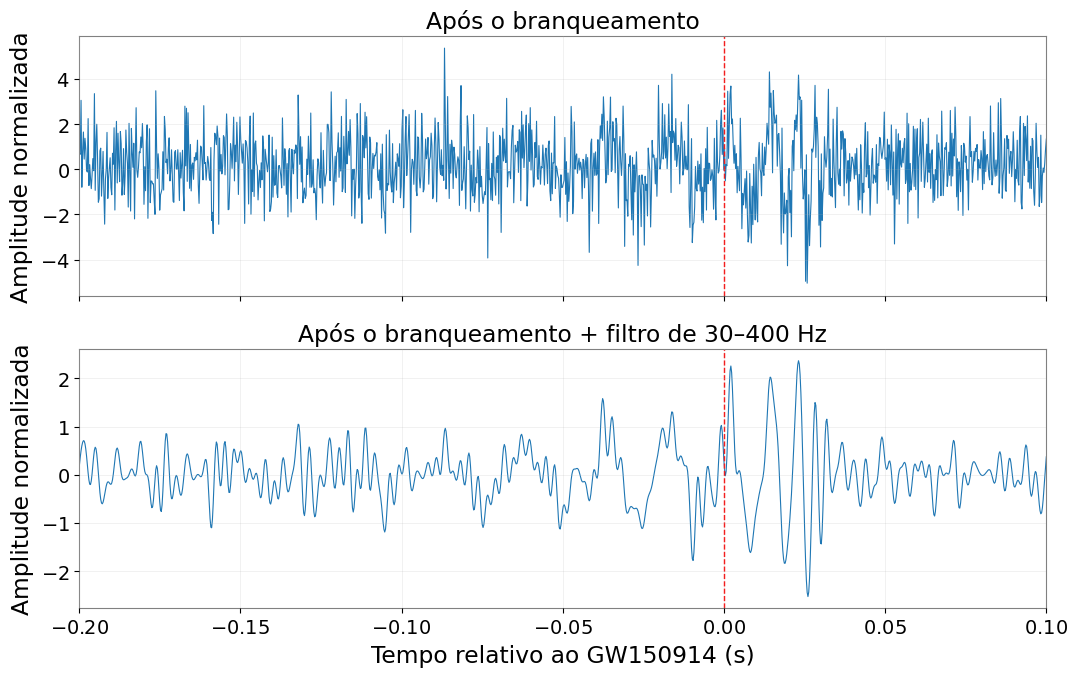

In [5]:
# Filtro passa-faixa de 30 a 400 Hz sobre a série branqueada.
filtrado = branqueado.bandpass(30, 400)

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for eixo, serie, titulo in [
    (ax[0], branqueado, "Após o branqueamento"),
    (ax[1], filtrado, "Após o branqueamento + filtro de 30–400 Hz"),
]:
    eixo.plot(serie.times.value - GPS_EVENTO, serie.value, lw=0.8)
    eixo.axvline(0, color="red", ls="--", lw=1)
    eixo.set(ylabel="Amplitude normalizada", title=titulo)
    eixo.grid(alpha=0.25)
ax[-1].set(xlim=(-0.2, 0.1), xlabel="Tempo relativo ao GW150914 (s)")
plt.tight_layout()
plt.show()

#5. Transformada Q — representação tempo-frequência

A transformada Q (Q-transform) é uma técnica de análise de sinais que permite identificar quais frequências estão presentes e em que instantes elas aparecem. É especialmente útil na análise de ondas gravitacionais porque permite visualizar sinais de curta duração cuja frequência muda rapidamente, como o chirp do GW150914.

- Eixo horizontal: tempo relativo ao evento.
- Eixo vertical: frequência (Hz).
- Escala de cores: energia normalizada do mapa tempo-frequência.

O parâmetro $Q$ é o fator de qualidade, relacionado à razão entre a frequência central e a largura de banda:

$$Q = \frac{f_0}{\Delta f}$$.

Valores mais altos de $Q$ proporcionam melhor resolução em frequência e menor resolução temporal.

No GWpy, `qrange=(4, 64)` permite buscar diferentes valores de $Q$.

A transformada Q será aplicada **aos mesmos dados originais de 16 s**, com a ASD de referência fornecida ao branqueamento interno do algoritmo, e não diretamente à série que já foi branqueada e filtrada. Assim, evitamos aplicar o branqueamento duas vezes.

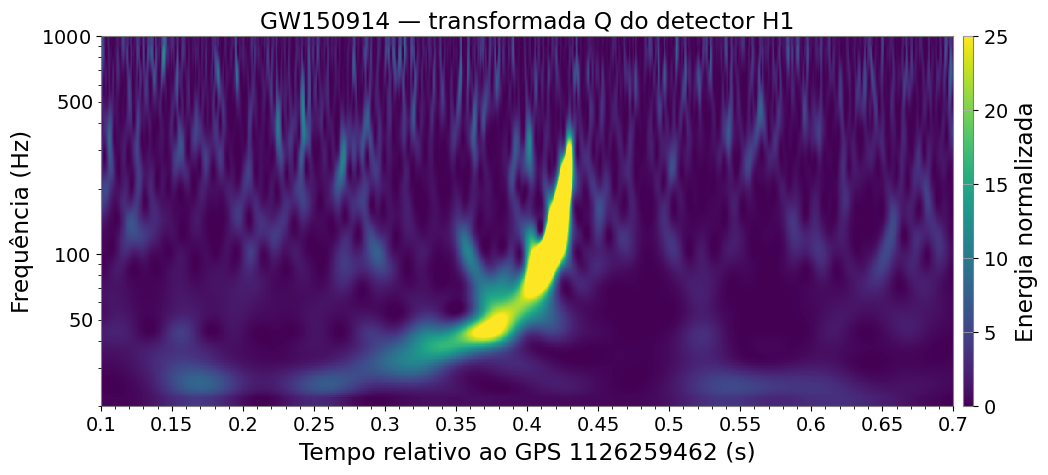

In [10]:

#----------------------------------------------------------
# Transformada Q — GW150914 (H1)
#----------------------------------------------------------

# Intervalo semelhante ao gráfico do GWOSC
gps_ref = int(GPS_EVENTO)

q = serie_evento.q_transform(
    outseg=(gps_ref + 0.1, gps_ref + 0.7),
    frange=(20, 1000),
    qrange=(4, 64),
    gps=GPS_EVENTO,
    whiten=asd_referencia,
    fduration=2,
    norm="median",
)

# Representar a transformada Q
fig = q.plot(figsize=(11, 5))
ax = fig.gca()

ax.set_epoch(gps_ref)
ax.set_xscale("seconds")
ax.set_yscale("log")
ax.set_ylim(20, 1000)

ax.set_xlabel("Tempo relativo ao GPS 1126259462 (s)")
ax.set_ylabel("Frequência (Hz)")
ax.set_title("GW150914 — transformada Q do detector H1")
ax.grid(False)

fig.colorbar(
    cmap="viridis",
    clim=(0, 25),
    label="Energia normalizada"
)

plt.show()


## Intepretando o espectrograma

No caso do GW150914, o sinal gravitacional foi produzido pela fusão de dois buracos negros.

Durante a fase de aproximação (inspiral), os buracos negros orbitam cada vez mais rapidamente. Como consequência, a frequência e a amplitude das ondas gravitacionais aumentam até as proximidades da fusão.

Esse comportamento produz a característica assinatura de um chirp.

Na representação tempo-frequência, observamos uma trajetória que se desloca das baixas para as altas frequências à medida que o tempo avança.

A transformada Q é particularmente adequada para revelar essa evolução, sendo utilizada também para investigar transientes de ruído instrumental (glitches) dos detectores LIGO e Virgo.

## Como interpretar o gráfico?

O eixo horizontal representa o tempo relativo ao evento; o vertical, a frequência; e as cores indicam a energia normalizada obtida pela transformada Q.

As regiões mais brilhantes identificam concentrações mais intensas de energia tempo-frequência em relação à normalização adotada. Não representam diretamente a amplitude física do strain.

No GW150914, a estrutura brilhante e ascendente corresponde à evolução rápida da frequência do sinal gravitacional.

#6. Aprofundando o conceito de transformada $Q$

A transformada de Fourier (FFT) permite decompor um sinal em suas componentes de frequência. Entretanto, quando calculamos a FFT de um intervalo completo de 16 segundos, obtemos informações sobre as frequências presentes durante esse intervalo, mas não sabemos exatamente quando cada componente ocorreu.

Uma solução é dividir o sinal em pequenos intervalos temporais e calcular uma FFT para cada um deles. Esse procedimento é conhecido como transformada de Fourier de curta duração (STFT) e permite construir um espectrograma.

O problema é que a STFT convencional utiliza uma janela com duração fixa.

A transformada Q adota uma estratégia diferente: utiliza janelas de análise cujas durações variam com a frequência. Isso permite adaptar a resolução temporal e espectral às características do sinal.


## Uma analogia da transformada Q como Um fator de qualidade

O fator de qualidade, é definido por

$$Q = \frac{f_0}{\Delta f}$$.

em que:
- $f_0$ é a frequência central de uma determinada região analisada;
- $\Delta f$ é a largura da faixa de frequências associada a essa região.
Portanto, o fator $Q$ estabelece uma relação entre a frequência central e a largura da banda analisada.

Para um valor fixo de $Q$:
$$
\Delta f=\frac{f_0}{Q}.
$$

Isso significa que regiões de frequências mais altas são analisadas utilizando bandas espectrais mais largas.

Como existe uma relação de compromisso entre as resoluções temporal e espectral, podemos escrever, aproximadamente,

$$
\Delta t\sim\frac{Q}{f_0}.
$$

Aqui, $\Delta t$ representa a escala temporal da janela de análise, e não o intervalo de amostragem $\Delta t=1/f_s$ utilizado anteriormente no notebook. Para evitar essa ambiguidade, podemos chamar essa escala de $\tau$:

$$
\tau\sim\frac{Q}{f_0}.
$$

As constantes de proporcionalidade dependem da definição de largura temporal e espectral adotada.

##  Comparação entre FFT, STFT e transformada Q

| Técnica | Característica principal | Informação obtida |
|:---:|:---|:---|
| **FFT** | Analisa o intervalo temporal completo | Quais frequências estão presentes |
| **STFT** | Utiliza janelas temporais de duração fixa | Como o conteúdo espectral evolui no tempo |
| **Transformada Q** | Utiliza janelas com duração dependente da frequência | Evolução tempo-frequência com resolução adaptativa |

<div align="center">

<img src="https://raw.githubusercontent.com/Ronai/gwd/0e3d458669830068739026a7520b7781ee1d1dd6/introduction_gwosc_data/img/ligo%20-%20sfft.png" width="750">

</div>



#7. Questões para discussão

1. Por que o branqueamento utiliza uma ASD de referência calculada antes do evento, e não o sinal gravitacional isolado?
2. Comparando os dois gráficos da Seção 2, o que mudou após a filtragem passa-faixa?
3. Qual característica do *chirp* do GW150914 aparece na transformada Q e não fica evidente na FFT de todo o intervalo?
4. O que ocorre com a resolução temporal e a resolução em frequência quando aumentamos o fator Q?

**Referências:** [GWOSC](https://gwosc.org/) · [Documentação do GWpy](https://gwpy.github.io/docs/stable/)